## Lab5-Assignment (Hawra Almadeh)

### 1. Import Dependencies and Load Dataset

In [38]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

In [39]:
DATA_PATH = "talabat_enhanced_orders2.csv" 
df = pd.read_csv(DATA_PATH)

df.head(10)

,Order_ID,User_ID,Restaurant_ID,Driver_ID,Item_Name,Quantity,Total_Price,Order_Time,Delivery_Time,Delivery_Duration_Minutes,City,Payment_Method,Order_Status,Driver_Vehicle,Restaurant_Lat,Restaurant_Lon,Customer_Lat,Customer_Lon,Driver_Lat,Driver_Lon,Delivery_Distance_km,Traffic_Level,Driver_Availability
0,56795,U4934,991,313,Sushi,5,305.65,2025-06-11 14:37:00,2025-06-11 14:58:00,21,Giza,Wallet,Delivered,Car,30.011739,31.220610,30.019520,31.196654,30.026240,31.200332,2.466822,Medium,Online
1,81167,U8701,151,316,Pizza,4,446.40,2025-06-08 20:13:00,2025-06-08 20:49:00,36,Cairo,Cash,In Transit,Car,30.045413,31.223939,30.062724,31.220663,30.050536,31.237185,1.944823,Low,Online
2,75889,U7689,138,363,Koshary,3,394.50,2025-06-07 03:29:00,2025-06-07 04:20:00,51,Mansoura,Credit Card,Delivered,Car,31.057534,31.366192,31.045638,31.373109,31.020001,31.399328,1.475038,Low,Online
3,34786,U7076,540,258,Burger,4,139.20,2025-06-09 20:49:00,2025-06-09 21:30:00,41,Tanta,Wallet,Cancelled,Bicycle,30.787492,30.993809,30.789228,30.984042,30.805722,30.997262,0.954482,Low,Online
4,38475,U6245,847,110,Salad,2,207.02,2025-06-08 12:05:00,2025-06-08 12:33:00,28,Tanta,Credit Card,Cancelled,Bicycle,30.803427,30.983386,30.768538,30.992124,30.792271,30.987854,3.957460,Medium,Online
5,88329,U3379,454,90,Sandwich,1,125.68,2025-06-02 04:02:00,2025-06-02 04:33:00,31,Alexandria,Cash,Delivered,Car,31.180300,29.922967,31.180552,29.899449,31.211355,29.929651,2.242070,Low,Online
6,79499,U3029,168,479,Sushi,2,243.62,2025-06-15 01:06:00,2025-06-15 01:59:00,53,Giza,Credit Card,Delivered,Motorbike,30.013826,31.215348,30.020233,31.228303,29.995995,31.212204,1.437552,Low,Online
7,27325,U3674,473,321,Fried Chicken,1,149.87,2025-06-04 01:02:00,2025-06-04 01:53:00,51,Tanta,Cash,Cancelled,Car,30.794454,30.998586,30.791487,31.002607,30.799764,31.006845,0.506267,Low,Online
8,73621,U8696,704,42,Pasta,4,562.32,2025-06-14 06:45:00,2025-06-14 07:33:00,48,Zagazig,Credit Card,Delivered,Car,30.573653,31.508104,30.602105,31.519432,30.587649,31.500689,3.336044,Low,Online
9,18180,U3260,458,183,Pasta,5,194.95,2025-06-03 02:50:00,2025-06-03 03:15:00,25,Alexandria,Cash,Delivered,Motorbike,31.193297,29.906175,31.187237,29.913781,31.202042,29.926440,0.988472,Low,Online


### 2. Feature Engineering

#### 2.1 Removing Leakage Features

In [40]:
leakage_cols = ["Delivery_Time", "Delivery_Duration_Minutes"]
df_fe = df.drop(columns=[c for c in leakage_cols if c in df.columns])

#### 2.2 Convert Order_Time

In [41]:
df_fe["Order_Time"] = pd.to_datetime(df["Order_Time"], errors="coerce")

df_fe["order_hour"] = df_fe["Order_Time"].dt.hour
df_fe["order_dayofweek"] = df_fe["Order_Time"].dt.dayofweek  # Monday=0, Sunday=6
df_fe["is_weekend"] = df_fe["order_dayofweek"].isin([5,6]).astype(int)

df_fe["is_peak_hour"] = df_fe["order_hour"].isin(list(range(12,16)) + list(range(19,24))).astype(int)

#### 2.3 Create Price_Per_Item and Discretization of Total_Price

In [42]:
df_fe["price_per_item"] = df_fe["Total_Price"] / df_fe["Quantity"]

df_fe["price_tier"] = pd.cut(
    df_fe["Total_Price"],
    bins=[0, 100, 250, 500, np.inf],
    labels=["low","medium","high","very_high"]
)

#### 2.4 Dropping ID Columns

In [43]:
drop_base_cols = ["Order_ID", "User_ID", "Restaurant_ID", "Driver_ID", "Order_Time"]
df_fe = df_fe.drop(columns=[c for c in drop_base_cols if c in df_fe.columns])

### 3. Stepup for Experiments

> **Important Note:** In the following section I created two functions, one for making the model and pipeline and another for feature importance to reuse throughout the comparison to prevent redundent code.

#### 3.1 Model nad Pipeline Function

In [44]:
def Pipeline_Creating(df_fe, top_k):
    
    top_items = df_fe["Item_Name"].value_counts().head(top_k).index
    df_fe["Item_Name_reduced"] = np.where(df_fe["Item_Name"].isin(top_items), df_fe["Item_Name"], "Other")
    df_fe = df_fe.drop(columns=["Item_Name"])
    
    X = df_fe.drop(columns=["Order_Status"])
    y = df_fe["Order_Status"]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    categorical_cols = X_train.select_dtypes(include=["object", "category", "str"]).columns.tolist()
    numeric_cols = X_train.select_dtypes(include=[np.number, "bool"]).columns.tolist()
    
    preprocess = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", "passthrough", numeric_cols),
        ]
    )

    rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)
    
    model = Pipeline(steps=[
        ("preprocess", preprocess),
        ("rf", rf)
    ])
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    print(f"Experiment Metrics for top_k {top_k}:")
    print(f"Accuracy Score: {acc:.4f}\n")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=model.classes_, yticklabels=model.classes_)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    # Return the trained model along with training features for the next function
    return model, categorical_cols, numeric_cols


#### 3.2 Features Importance Function

In [45]:
def Feature_Importance(model_pipeline, cat_cols, num_cols):

    ohe = model_pipeline.named_steps["preprocess"].named_transformers_["cat"]
    cat_feature_names = ohe.get_feature_names_out(cat_cols) if len(cat_cols) > 0 else np.array([])
    all_feature_names = np.concatenate([cat_feature_names, np.array(num_cols)])
    
    importances = model_pipeline.named_steps["rf"].feature_importances_
    
    fi_df = pd.DataFrame({"feature": all_feature_names, "importance": importances})
    fi_df = fi_df.sort_values("importance", ascending=False).reset_index(drop=True)

    display(fi_df.head(15))
    
    plt.figure(figsize=(8, 5))
    sns.barplot(data=fi_df.head(15), x="importance", y="feature")
    plt.title(f"Top 15 Features Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
    
    return 

### 4. top_k Comparison

#### 4.1 top_k =3

First create pipline, train and test the model, then unpack the values for model, categorical and numerical columns to pass to the feature importance function later.

Experiment Metrics for top_k 3:
Accuracy Score: 0.4010

              precision    recall  f1-score   support

   Cancelled       0.40      0.47      0.43      1963
   Delivered       0.41      0.53      0.46      2039
  In Transit       0.26      0.01      0.01       998

    accuracy                           0.40      5000
   macro avg       0.36      0.33      0.30      5000
weighted avg       0.37      0.40      0.36      5000



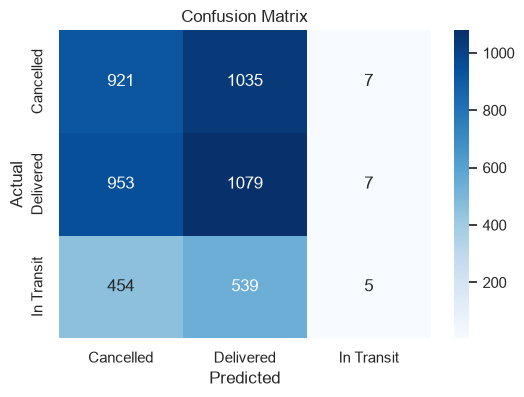

,feature,importance
0,Delivery_Distance_km,0.079150
1,Driver_Lon,0.076973
2,Driver_Lat,0.076915
3,price_per_item,0.076812
4,Customer_Lon,0.076481
5,Customer_Lat,0.076217
6,Restaurant_Lat,0.076056
7,Restaurant_Lon,0.075821
8,Total_Price,0.075276
9,order_hour,0.053790


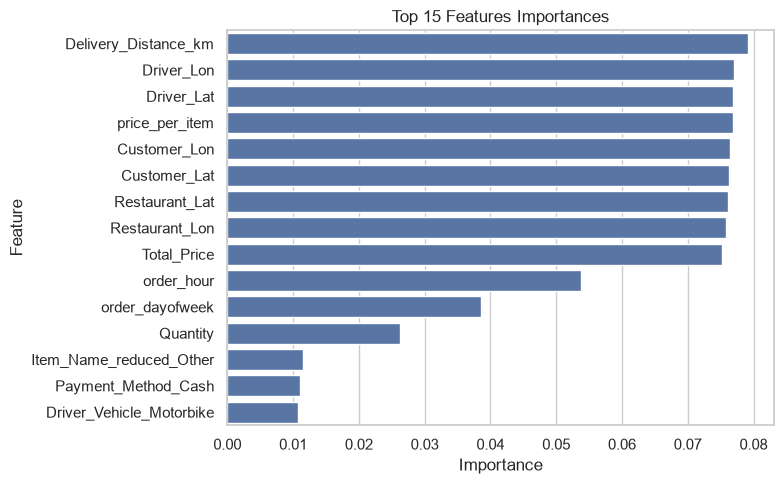

In [46]:
model, categorical_cols, numeric_cols = Pipeline_Creating(df_fe, top_k=3)
Feature_Importance(model, categorical_cols, numeric_cols)

After changing the top_k value to 3, we can see how this slighly improved the overall accuracy of the model from 0.393 for top_k =9 as seen in the lab to 0.40. The classification report also presents almost identical results to when k was 9 with precision scores of 0.39, 0.40 and 0.23 compared to the k=9 0.38, 0.40, and 0.17 for Cancelled, Dlivered and In Transit respectevly which suggests the model still able to correcly predict the data, even with less features.

On the other hand, we can see how this changes the top important features. the price_per_item feature dropped 2 ranks from the its original second place when top_k was 9. Conversly, Diver_Lon has been raised 2 ranks. In addition the last feature which was Payment_Method_Wallet in the k=9 plot got replaced with Driver_Vechle_Motorbike.

#### 4.2 top_k=5

Experiment Metrics for top_k 5:
Accuracy Score: 0.3936

              precision    recall  f1-score   support

   Cancelled       0.39      0.46      0.42      1963
   Delivered       0.40      0.52      0.45      2039
  In Transit       0.23      0.01      0.01       998

    accuracy                           0.39      5000
   macro avg       0.34      0.33      0.29      5000
weighted avg       0.36      0.39      0.35      5000



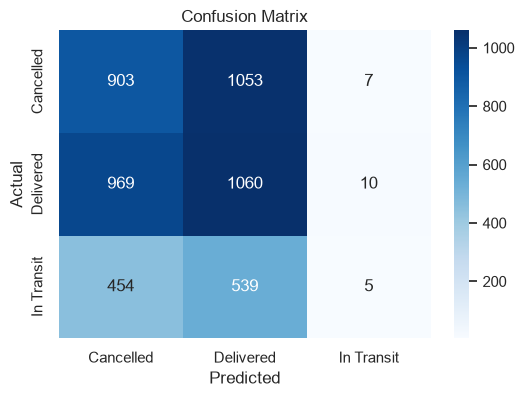

,feature,importance
0,Delivery_Distance_km,0.077527
1,price_per_item,0.075292
2,Driver_Lat,0.074869
3,Driver_Lon,0.074764
4,Customer_Lon,0.074686
5,Restaurant_Lon,0.074290
6,Total_Price,0.074175
7,Customer_Lat,0.073875
8,Restaurant_Lat,0.073844
9,order_hour,0.053012


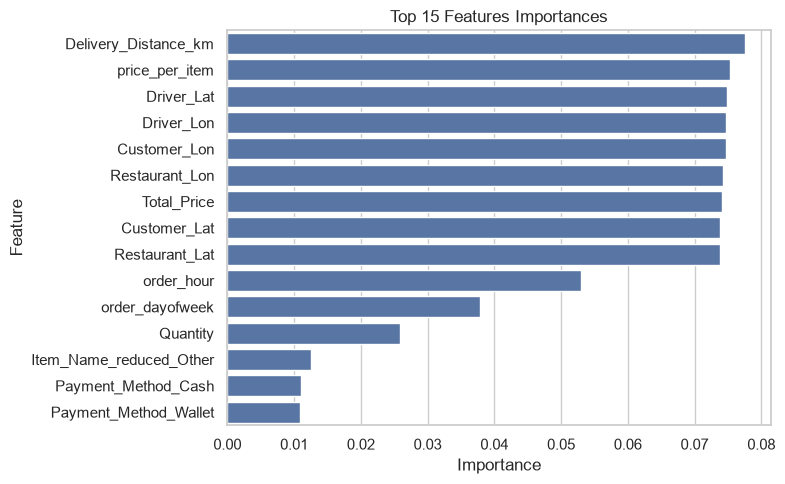

In [47]:
model, categorical_cols, numeric_cols = Pipeline_Creating(df_fe, top_k=5)
Feature_Importance(model, categorical_cols, numeric_cols)

As we can observe from the accuracy results. Setting top k to 5 yeilded the exact same accuracy as when k was 9. which is less than the accuracy of having three features (k=3). On another note the model confusion with Cancelled orders has increased from 1035 in the k=3 to 1053. Similarly, the correct predicted cases of Delivered dropped from 1079 to 1060 with the moel confusing 969 which 16 more than when k was 3.

From the feature importance table, we can see how total price dropped two ranks. Payment_Method_Wallet took last place instead of Driver_Vehicle_Motorbike. Customer_Lon and Restaurant_Lon take presedance at places 4 nad 5 over Customer_Lat and Restaurant_Lat which were at 5 and 6 places when k was 3. Meanwhile, Delivery_Distance still the top most important feature.

#### 4.3 top_k=6

Experiment Metrics for top_k 6:
Accuracy Score: 0.3916

              precision    recall  f1-score   support

   Cancelled       0.38      0.45      0.41      1963
   Delivered       0.40      0.52      0.45      2039
  In Transit       0.24      0.00      0.01       998

    accuracy                           0.39      5000
   macro avg       0.34      0.33      0.29      5000
weighted avg       0.36      0.39      0.35      5000



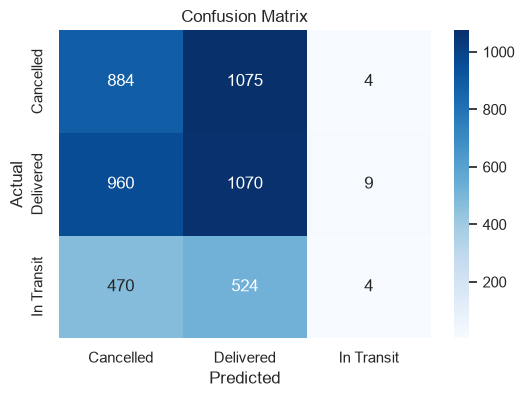

,feature,importance
0,Delivery_Distance_km,0.076411
1,price_per_item,0.074331
2,Driver_Lon,0.074176
3,Driver_Lat,0.074169
4,Customer_Lon,0.073840
5,Customer_Lat,0.073780
6,Restaurant_Lat,0.073396
7,Restaurant_Lon,0.073021
8,Total_Price,0.072939
9,order_hour,0.052749


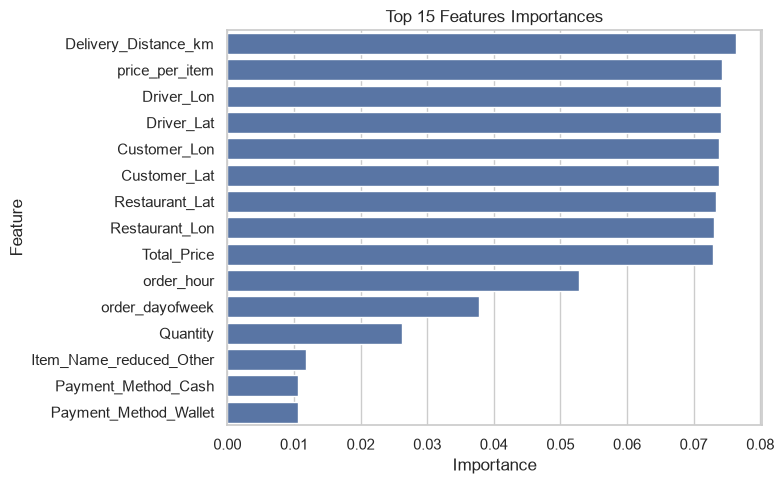

In [48]:
model, categorical_cols, numeric_cols = Pipeline_Creating(df_fe, top_k=6)
Feature_Importance(model, categorical_cols, numeric_cols)

As illustrated by the accuracy result and classification report the model performance did not degrade much from when k is 5. The accuracy suffured a decrease of 0.002 which is barely a change from 0.3936 of k=5. What is entriging is that the features from 10 to 14nth place are the smae for all k values. The most changes are centered around the middle of the importances table. As mentioned before the Distance attribute still accupying the top. In contrast Total price dropped two ranks taking the same place as in k=3 table. price_per_item is at second place again just like when k=5 and two ranks above from when k=3. The Driver_Lon , Driver_Lat and Customer_Lon, Customer_Lat are coming in similar order as when k=3.

### 5. Final Thoughts

It appears than the more features you have doesn't always mean a better results and higher accuracy. As observed from the experiments above the lowest value model outperformed models with higher values. It also suggets how can models achive higher results from the same data by adjusting the prameters and indroducing new features. The experiments explains how can small changes in the model parameters like choosing a value for top_k have a major effect on the overall model performance. This notes how important it is to choose the parameters and feature values wisely and carefully to help the model train and learn the data relationships and dependencies better.